# 항공사 승객 만족도 분석
### AI 빅데이터 전공 황태하

## 분석 목적
승객 특성과 비행 정보를 함께 고려했을 때, 어떤 서비스 평가가 전체 만족 여부와 관련이 있는지 알아본다.

## 데이터
Kaggle의 [Airline Passenger Satisfaction](https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction) 데이터를 사용했다. 한 행이 승객 한 명의 설문 응답이고, `train.csv` 103,904행과 `test.csv` 25,976행으로 나뉘어 있다.

| 구분 | 변수 |
|---|---|
| 결과변수 | `satisfaction` (만족=1, 중립 또는 불만족=0) |
| 승객 특성 | 성별, 나이, 고객 유형(충성/비충성) |
| 비행 정보 | 여행 목적, 좌석 등급, 비행거리, 출발·도착 지연시간(분) |
| 서비스 평가 14개 | 와이파이, 온라인 탑승수속, 좌석 편안함 등 1~5점 (0은 해당 없음) |

## 분석 순서
1. 환경 설정과 데이터 불러오기
2. 데이터 확인
3. 0값 제외
4. 집단별 만족 비율
5. 서비스 항목 간 Spearman 상관
6. 점수별 만족 비율
7. 로지스틱 회귀
8. 오즈비 표와 숲그림
9. 다중공선성 확인 (VIF)
10. 모형 비교 (M0 / M1 / M2)
11. 테스트 데이터 평가
12. 결론

## 1. 환경 설정과 데이터 불러오기

In [1]:
# !pip install pandas numpy statsmodels scikit-learn matplotlib seaborn

# 데이터 분석
import numpy as np
import pandas as pd
from pathlib import Path

# 통계 분석
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 모형 평가
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, log_loss, confusion_matrix

# 시각화
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 출력 설정 (Windows 기준 맑은고딕 폰트 사용)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

### 경로 설정
노트북은 `practice` 폴더에 있고 CSV 파일은 상위 폴더의 `source` 폴더에 있다. 그래프는 `practice/figures` 폴더에 저장한다.

In [2]:
BASE_DIR = Path.cwd()                      # 현재 노트북(practice 폴더) 위치
SOURCE_DIR = BASE_DIR.parent / 'source'    # data-analysis-practice/source 폴더
FIG_DIR = BASE_DIR / 'figures'             # 그래프 저장 폴더
FIG_DIR.mkdir(exist_ok=True)

SEED = 20261029   # 검증용 데이터 분할에 쓰는 시드

print('노트북 위치:', BASE_DIR)
print('데이터 폴더:', SOURCE_DIR)

노트북 위치: C:\Users\황태하\data-analysis-practice\practice
데이터 폴더: C:\Users\황태하\data-analysis-practice\source


In [3]:
train_raw = pd.read_csv(SOURCE_DIR / 'train.csv')
test_raw = pd.read_csv(SOURCE_DIR / 'test.csv')

print('train 크기:', train_raw.shape)
print('test 크기 :', test_raw.shape)
train_raw.head()

train 크기: (103904, 25)
test 크기 : (25976, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


## 2. 데이터 확인
### 변수 이름 정리
원래 열 이름은 공백과 기호가 있어서 회귀식에 쓰기 불편하다. 분석용 영어 이름으로 바꾸고, 그래프에는 한글 이름을 쓴다.

In [4]:
# 서비스 문항 14개: 원래 열 이름 -> 분석용 이름
service_columns = {
    'Inflight wifi service': 'wifi',
    'Departure/Arrival time convenient': 'time_convenient',
    'Ease of Online booking': 'online_booking',
    'Gate location': 'gate_location',
    'Food and drink': 'food_drink',
    'Online boarding': 'online_boarding',
    'Seat comfort': 'seat_comfort',
    'Inflight entertainment': 'entertainment',
    'On-board service': 'onboard_service',
    'Leg room service': 'leg_room',
    'Baggage handling': 'baggage',
    'Checkin service': 'checkin',
    'Inflight service': 'inflight_service',
    'Cleanliness': 'cleanliness',
}

# 분석용 이름 -> 그래프에 쓸 한글 이름
service_labels = {
    'wifi': '기내 와이파이',
    'time_convenient': '출도착 시간 편의',
    'online_booking': '온라인 예약 편의',
    'gate_location': '탑승구 위치',
    'food_drink': '기내식·음료',
    'online_boarding': '온라인 탑승수속',
    'seat_comfort': '좌석 편안함',
    'entertainment': '기내 엔터테인먼트',
    'onboard_service': '기내 응대',
    'leg_room': '다리 공간',
    'baggage': '수하물 처리',
    'checkin': '체크인 서비스',
    'inflight_service': '기내 서비스',
    'cleanliness': '청결도',
}

# 승객 특성과 비행 정보
other_columns = {
    'Gender': 'gender',
    'Customer Type': 'customer',
    'Age': 'age',
    'Type of Travel': 'travel',
    'Class': 'cabin',
    'Flight Distance': 'distance',
    'Departure Delay in Minutes': 'departure',
    'Arrival Delay in Minutes': 'arrival',
}

services = list(service_columns.values())

In [5]:
def prepare(raw):
    df = raw.rename(columns={**service_columns, **other_columns})
    df['y'] = (df['satisfaction'] == 'satisfied').astype(int)   # 만족=1, 중립·불만족=0
    return df

train_all = prepare(train_raw)
test_all = prepare(test_raw)

train_all['y'].value_counts()

y
0    58879
1    45025
Name: count, dtype: int64

In [6]:
# 결측치가 있는 열만 확인
missing = pd.DataFrame({'train 결측': train_all.isna().sum(), 'test 결측': test_all.isna().sum()})
missing[missing.sum(axis=1) > 0]

,train 결측,test 결측
arrival,310,83


In [7]:
# 서비스 문항별 0값 개수
zero_counts = pd.DataFrame({
    '서비스': [service_labels[s] for s in services],
    'train 0값': train_all[services].eq(0).sum().values,
    'test 0값': test_all[services].eq(0).sum().values,
})
zero_counts

,서비스,train 0값,test 0값
0,기내 와이파이,3103,813
1,출도착 시간 편의,5300,1381
2,온라인 예약 편의,4487,1195
3,탑승구 위치,1,0
4,기내식·음료,107,25
5,온라인 탑승수속,2428,652
6,좌석 편안함,1,0
7,기내 엔터테인먼트,14,4
8,기내 응대,3,2
9,다리 공간,472,126


### 데이터 확인 결과
- train은 103,904행, test는 25,976행이고 열은 25개다. train에서 만족은 45,025건(43.3%), 중립·불만족은 58,879건이다.
- 결측은 도착 지연시간에만 있다(train 310건, test 83건). 회귀에서는 train 중앙값으로 채우고, 결측 여부를 따로 변수로 넣는다.
- 0값은 출도착 시간 편의(5,300건), 온라인 예약 편의(4,487건), 와이파이(3,103건), 온라인 탑승수속(2,428건)에 많다.

## 3. 0값 제외
Kaggle 설명에서 와이파이의 0은 '해당 없음'이고, 다른 항목의 0도 점수로 보기 어렵다. 그래서 서비스 14개가 모두 1~5점인 응답만 분석에 사용한다.

In [8]:
# 서비스 14개가 모두 1점 이상인 응답만 남긴다
train = train_all[train_all[services].ge(1).all(axis=1)].copy()
test = test_all[test_all[services].ge(1).all(axis=1)].copy()

print('train:', len(train_all), '->', len(train), f'({len(train_all) - len(train)}건 제외)')
print('test :', len(test_all), '->', len(test), f'({len(test_all) - len(test)}건 제외)')
print('train 만족 비율:', round(train['y'].mean(), 4))

train: 103904 -> 95704 (8200건 제외)
test : 25976 -> 23863 (2113건 제외)
train 만족 비율: 0.4259


train은 8,200건(7.9%)을 빼서 95,704건, test는 2,113건을 빼서 23,863건이 남았다. 남은 train의 만족 비율은 42.6%다.

## 4. 집단별 만족 비율
여행 목적, 좌석 등급, 고객 유형에 따라 만족 비율이 얼마나 다른지 먼저 본다.

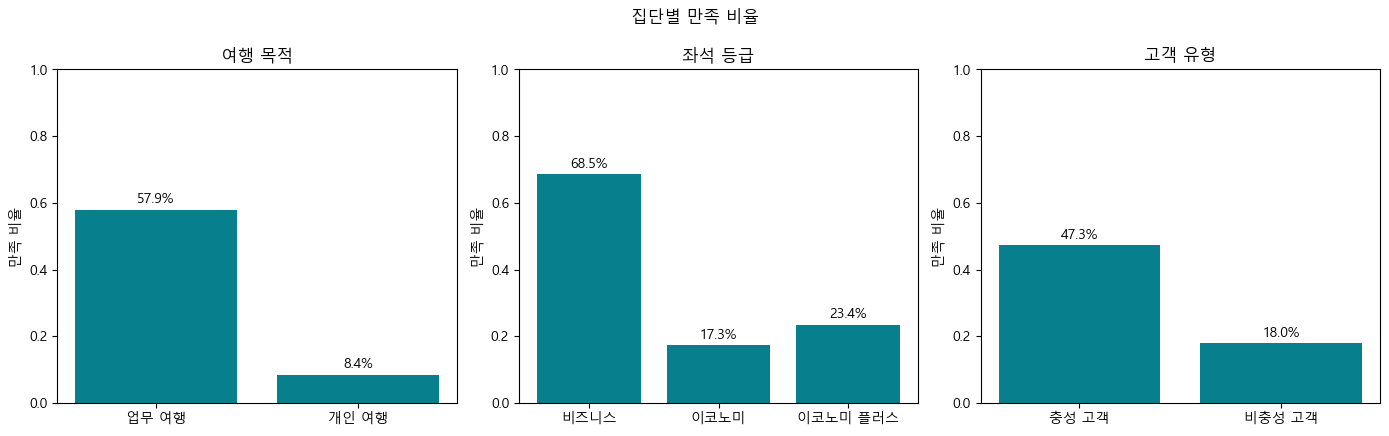

In [9]:
group_names = {'travel': '여행 목적', 'cabin': '좌석 등급', 'customer': '고객 유형'}
value_names = {
    'Business travel': '업무 여행', 'Personal Travel': '개인 여행',
    'Business': '비즈니스', 'Eco': '이코노미', 'Eco Plus': '이코노미 플러스',
    'Loyal Customer': '충성 고객', 'disloyal Customer': '비충성 고객',
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (col, title) in zip(axes, group_names.items()):
    rate = train.groupby(col)['y'].mean()
    ax.bar([value_names[v] for v in rate.index], rate.values, color='#087F8C')
    for i, v in enumerate(rate.values):
        ax.text(i, v + 0.02, f'{v:.1%}', ha='center')
    ax.set_ylim(0, 1)
    ax.set_ylabel('만족 비율')
    ax.set_title(title)

fig.suptitle('집단별 만족 비율')
fig.tight_layout()
fig.savefig(FIG_DIR / 'group_satisfaction.png', dpi=200, bbox_inches='tight')
plt.show()

In [10]:
# 집단별 표본 수와 만족 비율
for col, title in group_names.items():
    print(f'[{title}]')
    display(train.groupby(col)['y'].agg(['count', 'mean']).round(3))

[여행 목적]


,count,mean
travel,,
Business travel,66106,0.579
Personal Travel,29598,0.084


[좌석 등급]


,count,mean
cabin,,
Business,46464,0.685
Eco,42241,0.173
Eco Plus,6999,0.234


[고객 유형]


,count,mean
customer,,
Loyal Customer,80319,0.473
disloyal Customer,15385,0.180


### 집단별 만족 비율 해석
- 여행 목적: 업무 여행 57.9%, 개인 여행 8.4%로 차이가 가장 크다.
- 좌석 등급: 비즈니스 68.5%, 이코노미 17.3%, 이코노미 플러스 23.4%다.
- 고객 유형: 충성 고객 47.3%, 비충성 고객 18.0%다.

집단마다 만족 비율이 크게 다르기 때문에 회귀에서는 이 변수들을 조정변수로 함께 넣는다.

## 5. 서비스 항목 간 Spearman 상관
서비스 점수는 1~5점 순서형이라 Spearman 순위상관을 사용한다. 항목끼리 상관이 높으면 회귀에서 서로의 영향을 나눠 갖게 되므로 미리 확인해 둔다.

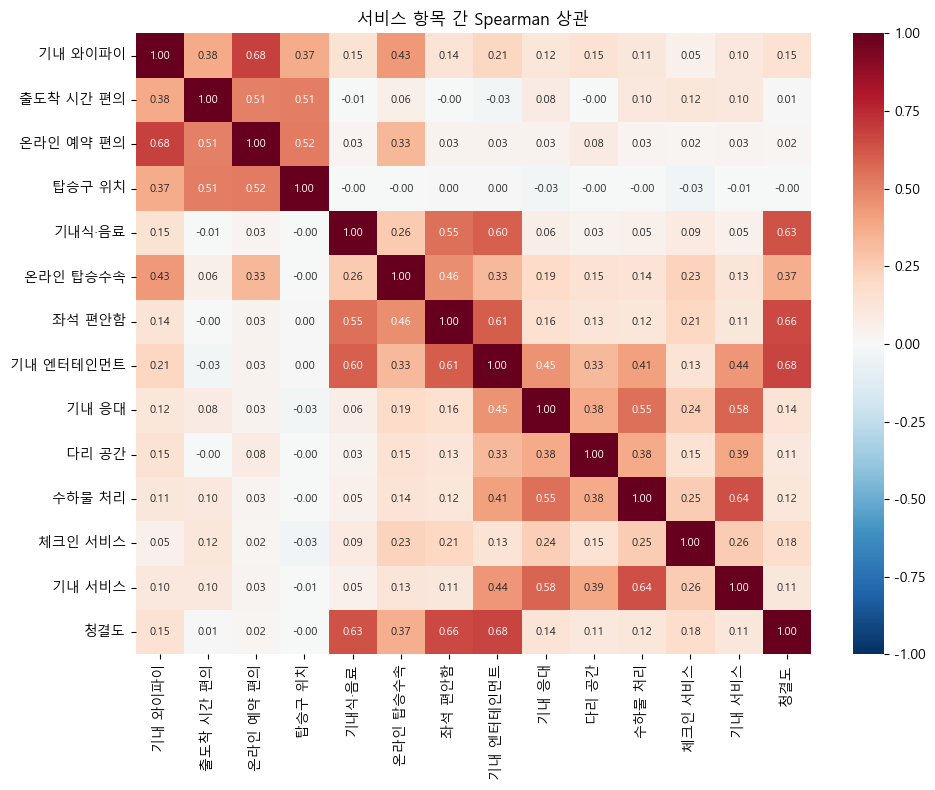

In [11]:
corr = train[services].corr(method='spearman')
corr_kr = corr.rename(index=service_labels, columns=service_labels)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_kr, cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 8}, ax=ax)
ax.set_title('서비스 항목 간 Spearman 상관')
fig.tight_layout()
fig.savefig(FIG_DIR / 'spearman_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

In [12]:
# 상관이 높은 항목 쌍 상위 5개 (대각선 위쪽만 사용)
upper = corr_kr.where(np.triu(np.ones(corr_kr.shape, dtype=bool), k=1))
upper.stack().sort_values(ascending=False).head(5).round(3)

기내 와이파이    온라인 예약 편의    0.680
기내 엔터테인먼트  청결도          0.675
좌석 편안함     청결도          0.663
수하물 처리     기내 서비스       0.644
기내식·음료     청결도          0.635
dtype: float64

### 상관분석 해석
와이파이–온라인 예약 편의(0.680), 엔터테인먼트–청결도(0.675), 좌석 편안함–청결도(0.663) 순으로 상관이 높았다. 서비스 평가끼리 꽤 겹치기 때문에, 회귀에서 다른 서비스를 함께 넣으면 단순 비교와 결과가 달라질 수 있다.

## 6. 점수별 만족 비율
온라인 탑승수속, 와이파이, 엔터테인먼트 세 항목에 대해 점수(1~5점)별 만족 비율을 꺾은선으로 그린다.

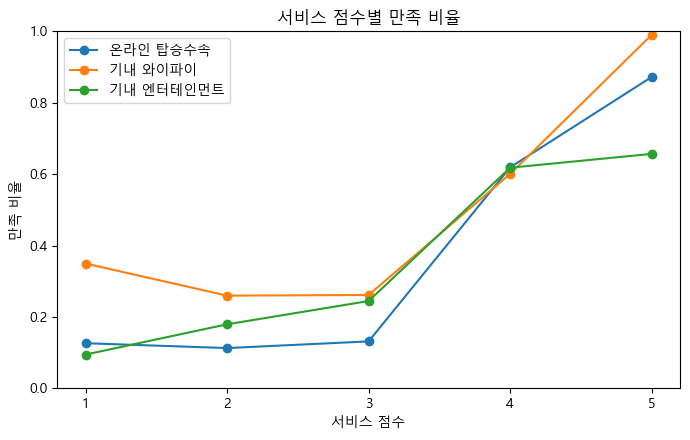

In [13]:
line_services = ['online_boarding', 'wifi', 'entertainment']

fig, ax = plt.subplots(figsize=(7, 4.5))
for s in line_services:
    rate = train.groupby(s)['y'].mean()
    ax.plot(rate.index, rate.values, marker='o', label=service_labels[s])

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_ylim(0, 1)
ax.set_xlabel('서비스 점수')
ax.set_ylabel('만족 비율')
ax.set_title('서비스 점수별 만족 비율')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'score_satisfaction.png', dpi=200, bbox_inches='tight')
plt.show()

In [14]:
score_rate = pd.DataFrame({service_labels[s]: train.groupby(s)['y'].mean() for s in line_services})
score_rate.index.name = '점수'
score_rate.round(3)

,온라인 탑승수속,기내 와이파이,기내 엔터테인먼트
점수,,,
1,0.127,0.350,0.095
2,0.113,0.260,0.180
3,0.132,0.262,0.245
4,0.619,0.601,0.618
5,0.872,0.990,0.657


### 점수별 만족 비율 해석
- 온라인 탑승수속은 1~3점에서 만족 비율이 11~13%로 비슷하다가 4점 61.9%, 5점 87.2%로 크게 오른다.
- 와이파이는 5점에서 99.0%로 거의 전부 만족이다. 1점(35.0%)이 2·3점(약 26%)보다 오히려 높다.
- 엔터테인먼트는 점수가 오를수록 꾸준히 올라가지만 5점도 65.7%에 그친다.

점수와 만족 비율이 직선 관계가 아니어서 회귀에서는 점수를 범주형으로 넣었다.

## 7. 로지스틱 회귀
결과변수가 만족/중립·불만족 두 가지라서 이항 로지스틱 회귀를 사용한다.

- 서비스 14개는 점수 간격이 같다고 보기 어려워서 **범주형**으로 넣고, **3점을 기준**으로 1·2·4·5점을 비교한다.
- 조정변수: 성별, 고객 유형, 여행 목적, 좌석 등급, 나이와 나이 제곱, 비행거리와 비행거리 제곱, log(1+도착 지연), 도착 지연 결측 여부
- 출발 지연과 도착 지연은 상관이 매우 높아서 도착 지연만 넣는다.
- 표준오차는 HC0 강건 표준오차를 쓴다.

In [15]:
arrival_median = train['arrival'].median()   # 도착 지연 결측은 train 중앙값으로 채움

def add_features(df, arrival_median):
    df = df.copy()
    df['age10'] = (df['age'] - 40) / 10                 # 나이: 40세 중심, 10세 단위
    df['age10_sq'] = df['age10'] ** 2
    df['dist1000'] = (df['distance'] - 1200) / 1000     # 비행거리: 1200 중심, 1000 단위
    df['dist1000_sq'] = df['dist1000'] ** 2
    df['arrival_missing'] = df['arrival'].isna().astype(int)
    df['arrival_log'] = np.log1p(df['arrival'].fillna(arrival_median))
    return df

train_model = add_features(train, arrival_median)
test_model = add_features(test, arrival_median)

In [16]:
# 세 모형에 공통으로 들어가는 조정변수
controls = ("C(gender, Treatment(reference='Female'))"
            " + C(customer, Treatment(reference='Loyal Customer'))"
            " + C(travel, Treatment(reference='Business travel'))"
            " + C(cabin, Treatment(reference='Business'))"
            " + age10 + age10_sq + dist1000 + dist1000_sq + arrival_log + arrival_missing")

# 서비스 14개를 3점 기준 범주형으로
service_terms = ' + '.join(f'C({s}, Treatment(reference=3))' for s in services)

formula_m2 = 'y ~ ' + controls + ' + ' + service_terms

In [17]:
model = smf.glm(formula_m2, data=train_model, family=sm.families.Binomial()).fit(maxiter=100, cov_type='HC0')

print('수렴 여부:', model.converged)
print('표본 수  :', int(model.nobs))
print('계수 개수:', len(model.params))

수렴 여부: True
표본 수  : 95704
계수 개수: 68


## 8. 오즈비 표와 숲그림
계수에 exp를 취하면 오즈비(OR)가 된다. 서비스별로 **5점 대 3점** 오즈비를 뽑아서 비교한다. OR이 1보다 크면 5점 응답자의 만족 오즈가 3점보다 높다는 뜻이다.

In [18]:
ci = model.conf_int()
or_table = pd.DataFrame({
    'OR': np.exp(model.params),
    'CI 하한': np.exp(ci[0]),
    'CI 상한': np.exp(ci[1]),
    'p값': model.pvalues,
})

# 서비스별 5점 대 3점 오즈비만 뽑기
service_or = or_table.loc[[f'C({s}, Treatment(reference=3))[T.5]' for s in services]]
service_or.index = [service_labels[s] for s in services]
service_or = service_or.sort_values('OR', ascending=False)
service_or.round(4)

,OR,CI 하한,CI 상한,p값
기내 와이파이,937.5893,633.5428,1387.5522,0.0000
온라인 탑승수속,18.7370,16.9171,20.7528,0.0000
좌석 편안함,4.8302,4.3285,5.3901,0.0000
기내 서비스,4.2450,3.7440,4.8131,0.0000
수하물 처리,4.0590,3.6270,4.5424,0.0000
다리 공간,2.4719,2.2500,2.7158,0.0000
체크인 서비스,2.0955,1.9300,2.2752,0.0000
기내 응대,1.8485,1.6653,2.0519,0.0000
청결도,1.6243,1.4621,1.8044,0.0000
온라인 예약 편의,1.4135,1.2049,1.6582,0.0000


In [19]:
# 조정변수의 오즈비
control_or = or_table.loc[[term for term in or_table.index if 'reference=3' not in term]]
control_or.round(4)

,OR,CI 하한,CI 상한,p값
Intercept,0.1548,0.1339,0.1789,0.0000
"C(gender, Treatment(reference='Female'))[T.Male]",1.0490,0.9938,1.1073,0.0827
"C(customer, Treatment(reference='Loyal Customer'))[T.disloyal Customer]",0.0313,0.0282,0.0349,0.0000
"C(travel, Treatment(reference='Business travel'))[T.Personal Travel]",0.0138,0.0121,0.0158,0.0000
"C(cabin, Treatment(reference='Business'))[T.Eco]",0.5801,0.5361,0.6277,0.0000
"C(cabin, Treatment(reference='Business'))[T.Eco Plus]",0.4818,0.4248,0.5465,0.0000
age10,0.9946,0.9735,1.0162,0.6227
age10_sq,0.9393,0.9281,0.9507,0.0000
dist1000,1.0250,0.9814,1.0704,0.2654
dist1000_sq,0.9937,0.9692,1.0189,0.6223


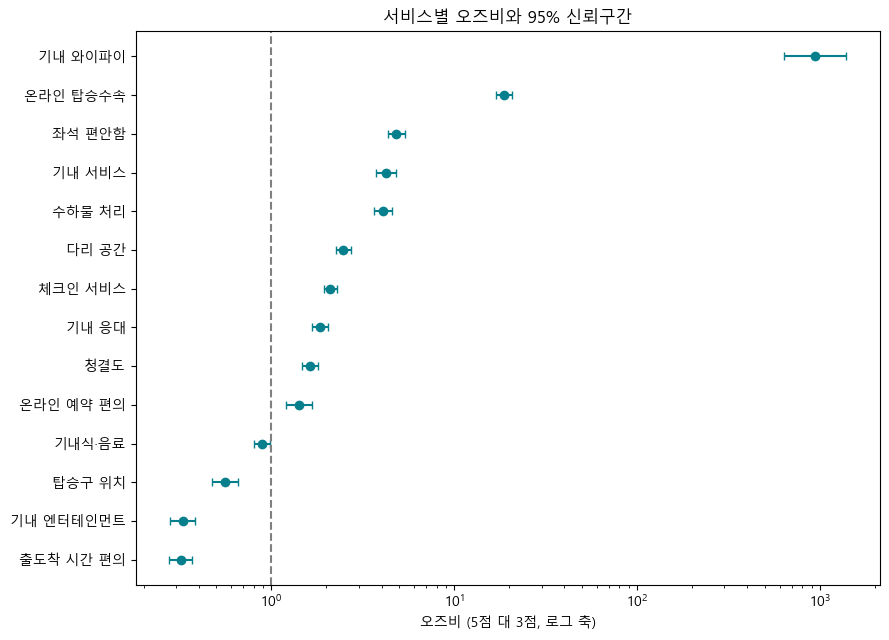

In [20]:
plot_df = service_or.iloc[::-1]   # 큰 값이 위에 오도록 뒤집기
y_pos = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.errorbar(plot_df['OR'], y_pos,
            xerr=[plot_df['OR'] - plot_df['CI 하한'], plot_df['CI 상한'] - plot_df['OR']],
            fmt='o', color='#087F8C', capsize=3)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index)
ax.set_xscale('log')
ax.axvline(1, linestyle='--', color='gray')
ax.set_xlabel('오즈비 (5점 대 3점, 로그 축)')
ax.set_title('서비스별 오즈비와 95% 신뢰구간')
fig.tight_layout()
fig.savefig(FIG_DIR / 'forest_plot.png', dpi=200, bbox_inches='tight')
plt.show()

### 오즈비 해석
- 온라인 탑승수속 5점의 만족 오즈는 3점보다 **18.74배**(95% CI 16.92~20.75) 높다. 다른 변수를 같게 놓고 비교한 값이고, 만족 확률이 18.74배라는 뜻은 아니다.
- 와이파이는 OR 937.6으로 매우 크다. 5점 응답자가 거의 다 만족(99.0%)이라서 생긴 값이고 신뢰구간도 넓다(633.5~1387.6).
- 좌석 편안함(4.83), 기내 서비스(4.25), 수하물 처리(4.06)도 OR이 컸다.
- 엔터테인먼트(0.327)와 출도착 시간 편의(0.320)는 1보다 작다. 6번 그래프에서는 엔터테인먼트 점수가 높을수록 만족 비율도 높았는데, 청결도·좌석처럼 상관이 높은 항목을 함께 넣고 비교하면서 방향이 바뀐 것으로 보인다.
- 조정변수 중에서는 개인 여행(OR 0.014)과 비충성 고객(OR 0.031)의 오즈비가 특히 작았다.

## 9. 다중공선성 확인 (VIF)
설계행렬(절편 제외)의 상관행렬 역행렬 대각원소가 각 변수의 VIF다. 보통 10을 넘으면 문제가 있다고 본다.

In [21]:
X = pd.DataFrame(model.model.exog, columns=model.model.exog_names).drop(columns='Intercept')
vif = pd.Series(np.diag(np.linalg.inv(X.corr().values)), index=X.columns, name='VIF')
vif.sort_values(ascending=False).head(10).round(3)

C(entertainment, Treatment(reference=3))[T.5]     5.661
C(entertainment, Treatment(reference=3))[T.4]     5.364
C(entertainment, Treatment(reference=3))[T.2]     5.343
C(entertainment, Treatment(reference=3))[T.1]     4.850
C(online_booking, Treatment(reference=3))[T.1]    3.961
C(online_booking, Treatment(reference=3))[T.2]    3.810
C(wifi, Treatment(reference=3))[T.1]              3.563
C(cleanliness, Treatment(reference=3))[T.2]       3.497
C(wifi, Treatment(reference=3))[T.2]              3.355
C(seat_comfort, Treatment(reference=3))[T.5]      3.344
Name: VIF, dtype: float64

가장 큰 VIF는 엔터테인먼트 5점 더미의 5.66이다. 10보다 작아서 심한 다중공선성은 없다고 판단했다. 다만 엔터테인먼트 더미들이 상위에 몰려 있어서, 앞의 OR 0.327은 다른 항목과 겹치는 부분을 생각하면서 봐야 한다.

## 10. 모형 비교 (M0 / M1 / M2)
서비스를 범주형으로 넣은 것이 나은지 확인하기 위해 세 모형을 비교한다.

| 모형 | 설명변수 |
|---|---|
| M0 | 조정변수만 |
| M1 | 조정변수 + 서비스 14개 점수형(1~5 숫자) |
| M2 | 조정변수 + 서비스 14개 범주형(3점 기준) |

train 분석 대상을 80:20으로 나눠서 80%로 적합하고 20%로 검증한다.

In [22]:
formulas = {
    'M0': 'y ~ ' + controls,
    'M1': 'y ~ ' + controls + ' + ' + ' + '.join(services),
    'M2': formula_m2,
}

fit_part, valid_part = train_test_split(train, test_size=0.2, stratify=train['y'], random_state=SEED)
fit_median = fit_part['arrival'].median()   # 검증에서는 적합용 데이터의 중앙값으로 채움
fit_part = add_features(fit_part, fit_median)
valid_part = add_features(valid_part, fit_median)

print('적합용:', len(fit_part), ' 검증용:', len(valid_part))

적합용: 76563  검증용: 19141


In [23]:
comparison = []
for name, formula in formulas.items():
    m = smf.glm(formula, data=fit_part, family=sm.families.Binomial()).fit(maxiter=100)
    prob = m.predict(valid_part)
    comparison.append({
        '모형': name,
        '계수 개수': len(m.params),
        '검증 log loss': log_loss(valid_part['y'], prob),
        '검증 AUC': roc_auc_score(valid_part['y'], prob),
    })

comparison = pd.DataFrame(comparison).set_index('모형')
comparison.round(4)

,계수 개수,검증 log loss,검증 AUC
모형,,,
M0,12,0.4498,0.8637
M1,26,0.2378,0.9648
M2,68,0.1763,0.9797


검증 log loss는 M0 0.450, M1 0.238, M2 0.176으로 M2가 가장 작고, AUC도 M2가 0.980으로 가장 높다. 서비스를 넣으면 성능이 크게 좋아지고, 점수형보다 범주형으로 넣는 쪽이 더 낫다. 그래서 최종 모형으로 M2를 사용한다.

## 11. 테스트 데이터 평가
train 전체로 적합한 M2를 test 분석 대상에 적용한다. 예측확률 0.5 이상이면 만족으로 분류한다.

In [24]:
test_prob = model.predict(test_model)
test_pred = (test_prob >= 0.5).astype(int)

print(f"테스트 정확도: {accuracy_score(test_model['y'], test_pred):.4f}")
print(f"테스트 AUC  : {roc_auc_score(test_model['y'], test_prob):.4f}")

테스트 정확도: 0.9330
테스트 AUC  : 0.9783


In [25]:
# 혼동행렬 (임계값 0.5)
cm = confusion_matrix(test_model['y'], test_pred)
pd.DataFrame(cm, index=['실제 중립·불만족', '실제 만족'], columns=['예측 중립·불만족', '예측 만족'])

,예측 중립·불만족,예측 만족
실제 중립·불만족,12896,694
실제 만족,904,9369


테스트 정확도는 **93.3%**, AUC는 **0.978**이다. 중립·불만족 694건을 만족으로, 만족 904건을 중립·불만족으로 잘못 분류했다. 검증 결과(AUC 0.980)와 비슷해서 과적합은 크지 않아 보인다.

## 12. 결론
| 단계 | 주요 결과 |
|---|---|
| 집단별 만족 비율 | 업무 여행 57.9% vs 개인 여행 8.4%, 비즈니스 68.5% vs 이코노미 17.3% |
| Spearman 상관 | 와이파이–예약 편의 0.680, 엔터테인먼트–청결도 0.675 |
| 로지스틱 회귀 | 온라인 탑승수속 5점 대 3점 OR 18.74, 좌석 편안함 OR 4.83 |
| 모형 비교 | M2가 검증 log loss 0.176, AUC 0.980으로 가장 좋음 |
| 테스트 평가 | 정확도 93.3%, AUC 0.978 |

승객 특성과 비행 정보를 고려해도 서비스 평가는 전체 만족과 강하게 관련되어 있었다. 그중 온라인 탑승수속은 오즈비가 크고 신뢰구간도 좁아서 가장 눈에 띄는 항목이었다.

### 한계
- 서비스 점수에 0이 있는 응답을 빼서 분석 대상이 전체 승객과 다를 수 있다.
- 관찰 자료라서 오즈비는 관련성을 보여줄 뿐 인과효과는 아니다.
- 서비스 평가와 전체 만족을 같은 설문에서 받아서 응답 경향이 겹칠 수 있다.
- 와이파이처럼 응답이 한쪽에 몰린 항목이나 엔터테인먼트처럼 다른 항목과 상관이 높은 항목은 오즈비 크기를 그대로 받아들이기 어렵다.